# Dominick's Finer Foods: how much of each manufacturer's cereal volume sells on a price cut?

A category manager's first question about promotions: which suppliers' volume depends on deals, and how deep are those deals? Reads the canonical tables written by `make onboard CLIENT=client_b`. Units are store x product x week units over the whole analysis window.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

client = "client_b"
sales = pl.read_parquet(f"../data/canonical/{client}/sales.parquet")
products = pl.read_parquet(f"../data/canonical/{client}/products.parquet")
sales.select(
    first_week=pl.col("week_start").min(),
    last_week=pl.col("week_start").max(),
    stores=pl.col("store_id").n_unique(),
    rows=pl.len(),
)

first_week,last_week,stores,rows
date,date,u32,u32
1993-05-13,1997-05-01,93,404447


In [2]:
cut = pl.col("on_price_cut")
by_manufacturer = (
    sales.join(products, on="product_id")
    .group_by("manufacturer")
    .agg(
        products=pl.col("product_id").n_unique(),
        units=pl.col("units").sum(),
        promo_units=pl.col("units").filter(cut).sum(),
        weeks_on_cut=cut.mean(),
        depth_on_cut=pl.col("discount_depth").filter(cut).mean(),
    )
    .with_columns(promo_share=pl.col("promo_units") / pl.col("units"))
    .sort("units", descending=True)
)
by_manufacturer

manufacturer,products,units,promo_units,weeks_on_cut,depth_on_cut,promo_share
str,u32,i64,i64,f64,f64,f64
"""Kellogg's""",15,8057242,4080153,0.155525,0.233489,0.506396
"""General Mills""",8,4498067,1804375,0.129747,0.230113,0.401145
"""Dominicks""",3,861194,372724,0.259189,0.197688,0.432799
"""Quaker""",1,568124,410655,0.298627,0.222446,0.722826
"""Post""",1,457567,186542,0.228607,0.218091,0.407682


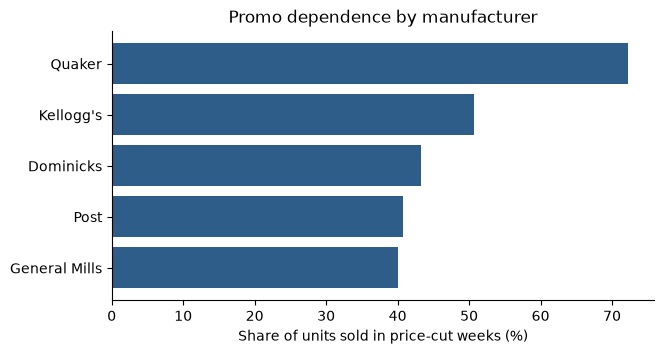

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
data = by_manufacturer.sort("promo_share")
ax.barh(data["manufacturer"], data["promo_share"] * 100, color="#2f5d8a")
ax.set_xlabel("Share of units sold in price-cut weeks (%)")
ax.set_title("Promo dependence by manufacturer")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Answer.** Deals carry the category. Kellogg's sells 51% of its units in the 16% of store-weeks it is on a price cut, at an average depth of 23%. General Mills is less dependent (40% of units, 13% of weeks). Quaker's one product, Cap'n Crunch, sells 72% of its units on deal. Dominick's own label is on a cut most often (26% of weeks) but at the shallowest depth (20%). So a pricing manager can't read Kellogg's regular-price volume as its baseline: half of it is promo-driven, and the promo calendar matters as much as the shelf price. Weeks with a cut are flagged by SALE code or a price 5%+ under the 8-week base price, since Dominick's doesn't code every deal.